# M1 Baseline Interface
The aim of of this notebook is to run OpenCV and try different models that will be capable to run on phone. It is also to try build a model with YOLO head and ViT backbone.

In [1]:
from ultralytics import YOLO
import cv2

## 1. Choosing a pretrained model
### 1.1 YOLOv8n
- YOLOv8n is the smallest and fastest model in the YOLOv8 family.
- It is designed for real-time applications and can run efficiently on devices with limited computational resources, such as mobile phones and embedded systems.
- It has fewer parameters and layers compared to larger models like YOLOv8m, YOLOv8l, and YOLOv8x, which makes it faster but may sacrifice some accuracy.

### 1.2 YOLOv8s
- YOLOv8s is a small model in the YOLOv8 family, offering a balance between speed and accuracy.
- It is suitable for applications that require real-time performance while still maintaining a reasonable level of accuracy.
- YOLOv8s has more parameters and layers than YOLOv8n, which can lead to improved detection performance, but it may be slightly slower.

<div style="text-align: center;">
<img src="https://a.storyblok.com/f/139616/1200x800/297c23f45f/structure-of-yolo.webp" width="600" alt="YOLO Architecture">
</div>
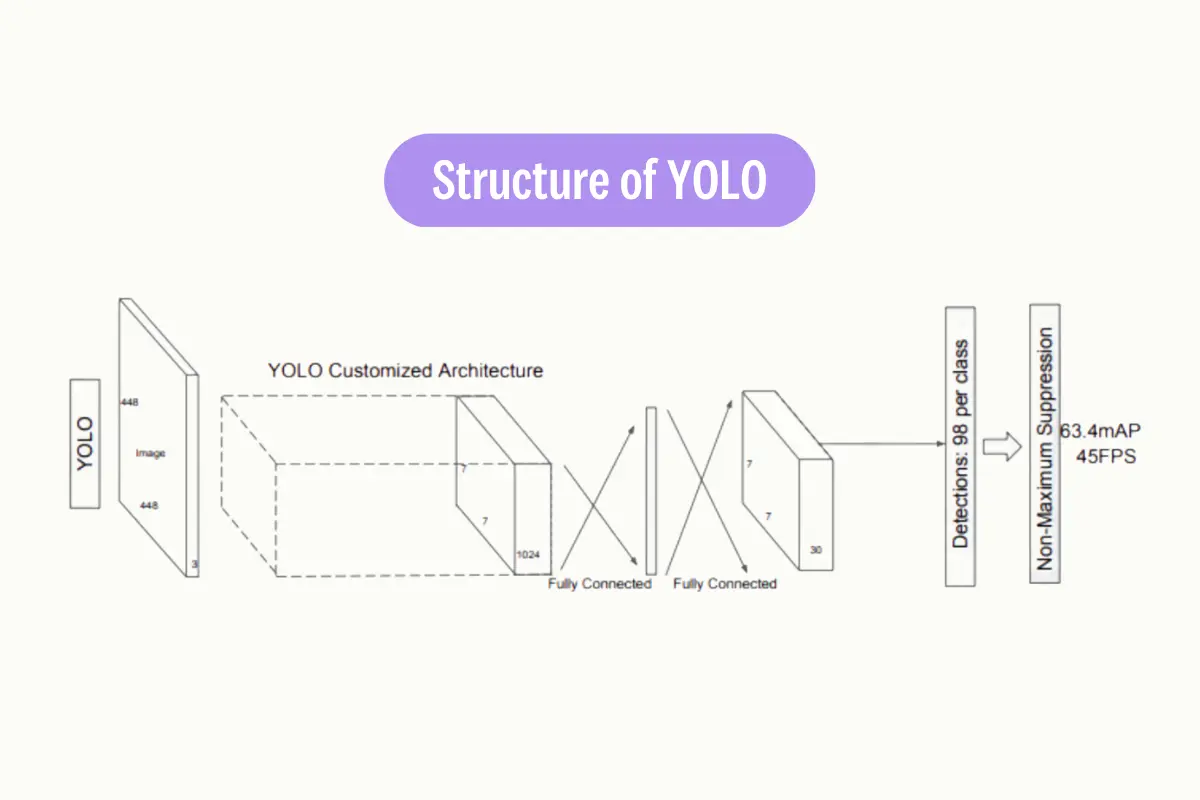

In [ ]:
model = YOLO("yolov8n.pt")

In [5]:
model = YOLO("yolov8s.pt")

In [2]:
model = YOLO("rtdetr-l.pt")

## 2. Running inference on webcam
Below is the code to run inference on webcam. You can change the model to any of the above models.
It uses OpenCV to capture video from the default camera (0) and display the annotated frames in a window. The loop continues until the ESC key is pressed.

In [ ]:
import time

cap = cv2.VideoCapture(0)
prev_time = time.time()

while True:
    ok, frame = cap.read()
    if not ok: break

    # Calculate FPS
    curr_time = time.time()
    fps = 1 / (curr_time - prev_time)
    prev_time = curr_time

    results = model(frame, imgsz=640, conf=0.25)
    annotated = results[0].plot()

    # Display FPS on frame
    cv2.putText(annotated, f"FPS: {fps:.2f}", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

    cv2.imshow("YOLOv8n", annotated)
    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()


## 3. ViT-style Backbone Demo
RT-DETR uses a transformer-based backbone (ViT-like).
### 3.1 RT-DETR
- RT-DETR is a lightweight version of the RT-DETR (Real-Time Detection Transformer) model, designed for real-time object detection tasks.
- It utilizes a transformer-based architecture, which allows it to capture long-range dependencies and contextual information more effectively than traditional convolutional neural networks (CNNs).
- RT-DETR is optimized for speed and efficiency, making it suitable for deployment on devices with limited computational resources, such as mobile phones and embedded systems.
<div style="text-align: center;">
<img src="https://github.com/ultralytics/docs/releases/download/0/baidu-rtdetr-model-overview.avif" width="900" alt="RT-DETR Architecture">
</div>


In [ ]:
model = YOLO("rtdetr-l.pt")  # or yolov8n.pt
cap = cv2.VideoCapture(0)
prev = time.time()

while True:
    ret, frame = cap.read()
    if not ret:
        break
    now = time.time()
    fps = 1 / (now - prev)
    prev = now

    results = model(frame)
    annotated = results[0].plot()
    cv2.putText(annotated, f"FPS: {fps:.2f}", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)
    cv2.imshow("Demo", annotated)
    if cv2.waitKey(1) == 27:
        break

cap.release()
cv2.destroyAllWindows()